In [1]:
import numpy as np
import scipy.stats as stats
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from dynamic_routing_analysis import decoding_utils
from dr_datacube import get_session_table
import dr_datacube
# from dynamic_routing_analysis import plot_utils
# from dynamic_routing_analysis import spike_utils

import os
# import pingouin as pg

import matplotlib
import matplotlib.font_manager as fm

matplotlib.rcParams['font.size'] = 8
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fm.FontProperties().set_family('arial')

%load_ext autoreload
%autoreload 2
%matplotlib inline
# %matplotlib notebook

In [ ]:
#supplemental decoding plots

In [2]:
#define paths

#vary units for strict drift
results_path_vary_n_units = [
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_1_units_min_40_units_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_2_units_min_40_units_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_min_40_units_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_min_40_units_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_min_40_units_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_min_40_units_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_min_40_units_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_min_40_units_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_40_units_min_40_units_0/",
]

# #also vary units for loose drift
# results_path_vary_n_units = [
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_1_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_2_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_min_40_units_loose_drift_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_40_units_min_40_units_loose_drift_0/",
# ]

# #5 units
# results_path_vary_drift = [
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0025_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_005_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0075_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_01_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0125_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_015_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0175_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_02_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_025_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_03_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_035_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_04_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_045_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_05_0/",
# ]

# #10 units
# results_path_vary_drift = [
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0025_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_005_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0075_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_01_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0125_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_015_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0175_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_02_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_025_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_03_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_035_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_04_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_045_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_050_0/",
# ]

#15 units - running now

# #also do this for 20 units
# results_path_vary_drift = [
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0025_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_005_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0075_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_01_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0125_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_015_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0175_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_02_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_025_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_03_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_035_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_04_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_045_1/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_05_1/",
# ]

#25 units - not running yet

# also for 30 units
results_path_vary_drift_30_units = [
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_05_0/",
]

# ##
# #20 units, 5 fold crossval
# results_path_vary_drift = [
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0025_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_005_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0075_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_01_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0125_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_015_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0175_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_02_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_025_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_03_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_035_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_04_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_045_5_fold_0/",
#     "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_05_5_fold_0/",
# ]

results_path_linear_shift="s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_strict_drift_linear_shift_0/"
results_path_blockwise_crossval="s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_context_500ms_leave_2_blocks_out_half_block_shifts_10_units_strict_drift_0/"


In [3]:
session_table_path=r"\\allen\programs\mindscope\workgroups\dynamicrouting\Ethan\CO decoding results\session_table_v0.289.parquet"

session_table=pl.read_parquet(session_table_path)

dr_session_list=(
    session_table.filter(
    pl.col('project')=="DynamicRouting",
    # pl.col('project')=="Templeton",
    pl.col('is_production'),
    pl.col('is_annotated'),
    pl.col('issues')==[],
    pl.col('is_opto_perturbation').eq(False),
    pl.col('is_injection_perturbation').eq(False),
    pl.col('is_context_naive').eq(False),
    # pl.col('is_good_behavior').eq(True),
    # pl.col('is_engaged').eq(True),
    )['session_id'].to_list()
    )

block_dprime_threshold=1.0

good_behavior_table={
    'session_id':[],
    'n_good_vis_blocks':[],
    'n_good_aud_blocks':[],
    'n_engaged_blocks':[],
}

for sel_session in dr_session_list:
    n_good_vis_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['cross_modality_dprime_vis_blocks'].to_numpy()[0]>=block_dprime_threshold)
    n_good_aud_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['cross_modality_dprime_aud_blocks'].to_numpy()[0]>=block_dprime_threshold)
    good_behavior_table['session_id'].append(sel_session)
    good_behavior_table['n_good_vis_blocks'].append(n_good_vis_blocks)
    good_behavior_table['n_good_aud_blocks'].append(n_good_aud_blocks)
    n_engaged_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['n_contingent_rewards'].to_numpy()[0]>=10)
    good_behavior_table['n_engaged_blocks'].append(n_engaged_blocks)

good_behavior_table=pd.DataFrame(good_behavior_table)
dr_session_list=good_behavior_table.query('n_good_vis_blocks>=2 and n_good_aud_blocks>=2 and n_engaged_blocks>=4')['session_id'].values

In [ ]:
#get unit metrics
# unit_metrics=dr_datacube.get_lf('unit_metrics', nwb=False)
unit_metrics_path=r"\\allen\programs\mindscope\workgroups\dynamicrouting\Ethan\CO single unit metrics\v289_2026-08-26\stim_context_lick_modulation.parquet"
unit_metrics=pd.read_parquet(unit_metrics_path)
unit_metrics['subject_id']=unit_metrics['session_id'].str[:6]
#regroup SC in SCs and SCm
sc_mapping = {
        'SCop': 'SCs',
        'SCsg': 'SCs',
        'SCzo': 'SCs',
        'SCig': 'SCm',
        'SCiw': 'SCm',
        'SCdg': 'SCm',
        'SCdw': 'SCm',
}
unit_metrics['structure'] = unit_metrics['structure'].replace(sc_mapping)

unit_metrics = decoding_utils.exclude_structures_from_df(unit_metrics)

In [ ]:
#get n areas that qualify based on min n units in each of n sessions
activity_drift_thresholds = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
min_n_units_per_session = [5, 10, 15, 20, 25, 30]
min_n_sessions_per_mouse = 1
min_n_mice = 3

n_passing_structures_drift_by_n_units_matrix=pd.DataFrame(index=activity_drift_thresholds, columns=min_n_units_per_session, dtype=int)
n_passing_sessions_drift_by_n_units_matrix=pd.DataFrame(index=activity_drift_thresholds, columns=min_n_units_per_session, dtype=int)

#filter by standard strict criteria
base_unit_query = 'decoder_label != "noise" & isi_violations_ratio <= 0.5 & amplitude_cutoff <= 0.1 & presence_ratio >= 0.7'

#find how many areas survive different minimum unit thresholds
#also compare across different drift criteria 

for ad in activity_drift_thresholds:
    for nn in min_n_units_per_session:
        
        unit_metrics_filtered = unit_metrics.query(base_unit_query+f' & activity_drift < {ad} and session_id in @dr_session_list')

        #group by session and structure to count units per session per structure
        units_per_session_structure = unit_metrics_filtered.groupby(['session_id', 'structure', 'subject_id']).size().reset_index(name='n_units')

        n_passing_sessions_per_structure = units_per_session_structure[units_per_session_structure['n_units'] >= nn].groupby('structure').size().reset_index(name='n_passing_sessions')
        n_passing_subjects_per_structure = units_per_session_structure[units_per_session_structure['n_units'] >= nn].groupby('structure')['subject_id'].nunique().reset_index(name='n_subjects')
   
        n_passing_structures = len(n_passing_sessions_per_structure.merge(n_passing_subjects_per_structure, on='structure')[n_passing_subjects_per_structure['n_subjects'] >= min_n_mice])

        n_passing_structures_drift_by_n_units_matrix.loc[ad, nn] = n_passing_structures
        n_passing_sessions_drift_by_n_units_matrix.loc[ad, nn] = n_passing_sessions_per_structure['n_passing_sessions'].sum()



In [ ]:
fig,ax = plt.subplots(figsize=(4,3.25))
im = ax.imshow(n_passing_structures_drift_by_n_units_matrix.values)
ax.set_xlabel('Minimum Units per Session')
ax.set_ylabel('Activity Drift Threshold')
ax.set_xticks(range(len(min_n_units_per_session)))
ax.set_xticklabels(min_n_units_per_session)
ax.set_yticks(range(len(activity_drift_thresholds)))
ax.set_yticklabels(activity_drift_thresholds)
ax.set_title('N Passing Structures by Drift and Units')
cb=fig.colorbar(im, ax=ax)

fig.tight_layout()

In [ ]:
fig,ax = plt.subplots(figsize=(4,3.25))
im = ax.imshow(n_passing_sessions_drift_by_n_units_matrix.values)
ax.set_xlabel('Minimum Units per Session')
ax.set_ylabel('Activity Drift Threshold')
ax.set_xticks(range(len(min_n_units_per_session)))
ax.set_xticklabels(min_n_units_per_session)
ax.set_yticks(range(len(activity_drift_thresholds)))
ax.set_yticklabels(activity_drift_thresholds)
ax.set_title('N Passing Structure-Sessions by Drift and Units')
cb=fig.colorbar(im, ax=ax)

fig.tight_layout()

In [ ]:
results_df_vary_n_units_list = [
    decoding_utils.load_structure_average_decoder_accuracy(
        path, 
        session_list=dr_session_list, 
        combine_multi_probe_rec=True, 
        exclude_redundant_structures=True, 
        exclude_general_structures=True,
        use_linear_shift=False,
    )
    for path in results_path_vary_n_units
]
results_df_vary_n_units = pl.concat(results_df_vary_n_units_list)



In [ ]:
results_df_vary_n_units['unit_criteria'].unique()

In [ ]:
#accuracy vs. n units for a subset of structures
results_pd=results_df_vary_n_units.to_pandas()

sel_structures=['SCm','MRN','MOs','FRP','ACAd','CP','PL','ORBl','CA1','VISp']
plot_column='mean_true'
err_column='sem_true'
min_n_sessions=3

# for ss in sel_structures[:1]:
#     fig,ax=plt.subplots(1,1,figsize=(4,3))
#     plot_data=results_pd.query('structure==@ss and num_sessions>=@min_n_sessions').sort_values(by=plot_column,ascending=True)

#     ax.errorbar(plot_data.query('~unit_subsample_size.isna()')['unit_subsample_size'],
#                 plot_data.query('~unit_subsample_size.isna()')[plot_column],
#                 yerr=plot_data.query('~unit_subsample_size.isna()')[err_column],marker='o',color='k')
#     # ax.errorbar(np.nanmax(plot_data['unit_subsample_size'])+10,
#     #             plot_data.query('unit_subsample_size.isna()')[plot_column],
#     #             yerr=plot_data.query('unit_subsample_size.isna()')[err_column],marker='o',color='k')
    
#     for uu in plot_data['unit_subsample_size'].unique():
#         if np.isnan(uu):
#             xcoord=np.nanmax(plot_data['unit_subsample_size'])+10
#             ycoord=plot_data.query('unit_subsample_size.isna()')[[plot_column,err_column]].sum(axis=1).values[0]
#             temp_str=plot_data.query('unit_subsample_size.isna()')['num_sessions'].values[0]
#         else:
#             xcoord=uu
#             ycoord=plot_data.query('unit_subsample_size==@uu')[[plot_column,err_column]].sum(axis=1).values[0]
#             temp_str=plot_data.query('unit_subsample_size==@uu')['num_sessions'].values[0]

#         ax.text(xcoord,ycoord,temp_str,ha='center',va='bottom')

#     ax.set_ylabel('decoding accuracy above null')
#     ax.set_xlabel('unit subsample size')
#     ax.set_xticks(plot_data['unit_subsample_size'].unique().tolist()+[np.nanmax(plot_data['unit_subsample_size'])+10])
#     # ax.set_xticklabels(plot_data['unit_subsample_size'].unique().astype(int).tolist()+['all_units'])
#     ax.set_title(ss)
#     # ax.set_ylim([0,0.2])
#     fig.tight_layout()

#plot all on same figure
fig,ax=plt.subplots(1,1,figsize=(5,3))
for ss in sel_structures:
    plot_data=results_pd.query('structure==@ss and num_sessions>=@min_n_sessions').sort_values(by=plot_column,ascending=True)

    line=ax.errorbar(plot_data.query('~unit_subsample_size.isna()')['unit_subsample_size'],
                plot_data.query('~unit_subsample_size.isna()')[plot_column],
                yerr=plot_data.query('~unit_subsample_size.isna()')[err_column],marker='o',label=ss)
    # ax.errorbar(np.nanmax(plot_data['unit_subsample_size'])+10,
    #             plot_data.query('unit_subsample_size.isna()')[plot_column],
    #             yerr=plot_data.query('unit_subsample_size.isna()')[err_column],marker='o',
    #             color=line[0].get_color())

#place legend outside axis
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_ylabel('decoding accuracy')
# ax.set_xscale('log')
ax.set_xlabel('unit subsample size')
ax.set_xticks(plot_data['unit_subsample_size'].unique().tolist())#+[np.nanmax(plot_data['unit_subsample_size'])+10])
# ax.set_xticklabels(plot_data['unit_subsample_size'].unique().astype(int).tolist()+['all_units'])
# ax.set_ylim([0,0.2])
fig.tight_layout()

In [ ]:
results_df_vary_drift_list = [
    decoding_utils.load_structure_average_decoder_accuracy(
        path, 
        session_list=dr_session_list, 
        combine_multi_probe_rec=True, 
        exclude_redundant_structures=True, 
        exclude_general_structures=True,
        use_linear_shift=False,
    )
    for path in results_path_vary_drift
]
results_df_vary_drift = pl.concat(results_df_vary_drift_list)

In [ ]:
# results_pd=results_df_vary_drift.to_pandas()
# results_pd.sort_values(by='unit_criteria')
sel_structure='SCm'
sel_unit_criteria='drift_0.1'
results_df_vary_drift.to_pandas().query("structure==@sel_structure and unit_criteria==@sel_unit_criteria")

In [ ]:
results_df_vary_n_units.to_pandas().query("structure==@sel_structure and unit_subsample_size==10")

In [ ]:
results_pd=results_df_vary_drift.to_pandas()

sel_structures=['SCm','MRN','MOs','ACAd','CP','VISp','context_module']

fig,ax=plt.subplots(1,1,figsize=(3,3))

for ss in sel_structures:
    sel_results=results_pd.query("structure == @ss").sort_values(by='unit_criteria')
    #convert drift criteria string to numeric values
    drift_criteria=sel_results['unit_criteria'].values
    drift_criteria_numeric=np.array([float(x.split('_')[-1]) for x in drift_criteria])
    ax.plot(drift_criteria_numeric, sel_results['mean_true'].values, '.-', label=ss)

    ax.fill_between(
        drift_criteria_numeric, sel_results['mean_true'].values - sel_results['sem_true'].values, 
        sel_results['mean_true'].values + sel_results['sem_true'].values, alpha=0.3)

ax.set_xlabel('Drift Criteria')
ax.set_ylabel('Mean True')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


In [ ]:
results_linear_shift_df = decoding_utils.load_structure_average_decoder_accuracy(
    results_path_linear_shift,
    session_list=dr_session_list, 
    combine_multi_probe_rec=True, 
    exclude_redundant_structures=True, 
    exclude_general_structures=True,
    use_linear_shift=True,
    ).to_pandas()

results_blockwise_crossval_df = decoding_utils.load_structure_average_decoder_accuracy(
    results_path_blockwise_crossval,
    session_list=dr_session_list, 
    combine_multi_probe_rec=True, 
    exclude_redundant_structures=True, 
    exclude_general_structures=True,
    use_linear_shift=False,
    ).to_pandas()

In [ ]:
merge_df=pd.merge(
    results_linear_shift_df,
    results_blockwise_crossval_df,
    on=['structure'],
    suffixes=('_linear_shift', '_blockwise_crossval'),
    how='outer'
)

r,p=stats.pearsonr(
    merge_df['mean_diff'],
    merge_df['mean_true_blockwise_crossval']
)

fig,ax=plt.subplots(1,1,figsize=(3,3))
ax.plot(
    merge_df['mean_diff'],
    merge_df['mean_true_blockwise_crossval'],
    'k.'
)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('Decoding accuracy above null (linear shift)')
ax.set_ylabel('Decoding accuracy (blockwise crossval)')
ax.set_title(f'Pearson r={r:.2f}, p={p:.2g}')

In [ ]:
# 20 units, loose drift
results_path_train_on_correct = "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_loose_drift_leave_2_blocks_out_train_on_correct_trials_0/"
results_path_leave_2_blocks_out = "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_loose_drift_leave_2_blocks_out_0/"
results_path_5x_5_fold = "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_loose_drift_5x_5_fold_0/"

In [ ]:
results_train_on_correct_df = decoding_utils.load_structure_average_decoder_accuracy(
    results_path_train_on_correct,
    session_list=dr_session_list, 
    combine_multi_probe_rec=True, 
    exclude_redundant_structures=True, 
    exclude_general_structures=True,
    use_linear_shift=False,
    ).to_pandas()

results_leave_2_blocks_out_df = decoding_utils.load_structure_average_decoder_accuracy(
    results_path_leave_2_blocks_out,
    session_list=dr_session_list, 
    combine_multi_probe_rec=True, 
    exclude_redundant_structures=True, 
    exclude_general_structures=True,
    use_linear_shift=False,
    ).to_pandas()

results_5x_5_fold_df = decoding_utils.load_structure_average_decoder_accuracy(
    results_path_5x_5_fold,
    session_list=dr_session_list, 
    combine_multi_probe_rec=True, 
    exclude_redundant_structures=True, 
    exclude_general_structures=True,
    use_linear_shift=False,
    ).to_pandas()

In [ ]:
#scatter plots by area

merge_df=pd.merge(results_train_on_correct_df, results_leave_2_blocks_out_df, on='structure', suffixes=('_train_on_correct', '_leave_2_blocks_out'))

fig,ax = plt.subplots(1,1,figsize=(4,4))
ax.plot([0, 1], [0, 1], 'k-',linewidth=0.5)
ax.plot(merge_df['mean_true_train_on_correct'], merge_df['mean_true_leave_2_blocks_out'], 'k.')
ax.set_xlim(0.45,0.85)
ax.set_ylim(0.45,0.85)
ax.set_xlabel('Train on Correct & L2BO')
ax.set_ylabel('Leave 2 Blocks Out')

In [ ]:
merge_df=pd.merge(results_5x_5_fold_df, results_leave_2_blocks_out_df, on='structure', suffixes=('_5x_5_fold', '_leave_2_blocks_out'))

fig,ax = plt.subplots(1,1,figsize=(3,3))
ax.plot([0, 1], [0, 1], 'k-',linewidth=0.5)
ax.plot(merge_df['mean_true_5x_5_fold'], merge_df['mean_true_leave_2_blocks_out'], 'k.')
ax.set_xlim(0.45,0.85)
ax.set_ylim(0.45,0.85)
ax.set_xlabel('5 fold (x5)\ndecoding accuracy')
ax.set_ylabel('Leave 2 blocks out\ndecoding accuracy')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()

In [ ]:
#Load session-wise train on correct and leave-2-blocks-out

results_session_train_on_correct_df=decoding_utils.load_session_wise_decoder_accuracy(results_path_train_on_correct, dr_session_list, session_table, use_linear_shift=False)
results_session_leave_2_blocks_out_df=decoding_utils.load_session_wise_decoder_accuracy(results_path_leave_2_blocks_out, dr_session_list, session_table, use_linear_shift=False)

In [ ]:
merge_session_df=pd.merge(results_session_train_on_correct_df.to_pandas(), results_session_leave_2_blocks_out_df.to_pandas(), on=['session_id','structure'], suffixes=('_train_on_correct', '_leave_2_blocks_out'))

In [ ]:
#filter areas by high decoding accuracy
sel_structures=results_train_on_correct_df.sort_values(by='mean_true', ascending=False)
sel_structures=sel_structures.query('mean_true >= 0.6 and num_sessions >= 3 and structure != "context_module"')['structure'].values

merge_session_df=merge_session_df[merge_session_df['structure'].isin(sel_structures)]

fig,ax=plt.subplots()
ax.plot(merge_session_df['mean_true_train_on_correct'], merge_session_df['mean_true_leave_2_blocks_out'], 'k.')
ax.set_xlabel('Train on Correct & L2BO')
ax.set_ylabel('Leave 2 Blocks Out')
ax.plot([0, 1], [0, 1], 'k-', linewidth=0.5)
ax.set_xlim(0.45, 0.85)
ax.set_ylim(0.45, 0.85)

In [ ]:
merge_session_df['mean_true_diff'] = merge_session_df['mean_true_train_on_correct'] - merge_session_df['mean_true_leave_2_blocks_out']

merge_session_df['mean_true_diff'].mean()

In [ ]:
# all 10 units, strict drift
results_path_standard_scaler="s3://aind-scratch-data/dynamic-routing/decoding/results/decode_context_baseline_10_units_strict_standard_scaler_0/"

results_path_l1_ratio_1_0="s3://aind-scratch-data/dynamic-routing/decoding/results/decode_context_baseline_10_units_strict_drift_l1_ratio_1.0_0/"

#default_params
results_path_default_params="s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_context_500ms_leave_2_blocks_out_half_block_shifts_10_units_strict_drift_0/"

In [ ]:
results_session_standard_scaler_df = decoding_utils.load_session_wise_decoder_accuracy(results_path_standard_scaler, dr_session_list, session_table, use_linear_shift=False)

results_session_l1_ratio_1_0_df = decoding_utils.load_session_wise_decoder_accuracy(results_path_l1_ratio_1_0, dr_session_list, session_table, use_linear_shift=False)

results_session_default_params_df=decoding_utils.load_session_wise_decoder_accuracy(results_path_default_params, dr_session_list, session_table, use_linear_shift=False)

In [ ]:
scaler_comp_merge = pd.merge(results_session_standard_scaler_df.to_pandas(), results_session_default_params_df.to_pandas(), on=["session_id", "structure"], suffixes=("_standard_scaler", "_robust_scaler"))

r,p=stats.pearsonr(scaler_comp_merge["mean_true_standard_scaler"], scaler_comp_merge["mean_true_robust_scaler"])

fig,ax = plt.subplots(figsize=(3,3))
ax.text(0.5, 0.9, f"r={r:.2f}, p={p:.2g}", transform=ax.transAxes)
ax.plot(scaler_comp_merge["mean_true_standard_scaler"], scaler_comp_merge["mean_true_robust_scaler"],'k.',alpha=0.2)
ax.set_xlabel("Standard Scaler Accuracy")
ax.set_ylabel("Robust Scaler Accuracy")
ax.set_title("Standard Scaler vs Robust Scaler Accuracy")
ax.plot([0.45, 1], [0.45, 1], 'r--', alpha=0.5)  # reference line for y=x
ax.set_xlim(0.45, 1)
ax.set_ylim(0.45, 1)


In [ ]:
l1_vs_l2_comp_merge = pd.merge(results_session_l1_ratio_1_0_df.to_pandas(), results_session_default_params_df.to_pandas(), on=["session_id", "structure"], suffixes=("_l1", "_l2"))

r,p=stats.pearsonr(l1_vs_l2_comp_merge["mean_true_l1"], l1_vs_l2_comp_merge["mean_true_l2"])
fig,ax = plt.subplots(figsize=(3,3))
ax.text(0.5, 0.9, f"r={r:.2f}, p={p:.2g}", transform=ax.transAxes)
ax.plot(l1_vs_l2_comp_merge["mean_true_l1"], l1_vs_l2_comp_merge["mean_true_l2"],'k.',alpha=0.2)
ax.set_xlabel("L1 Accuracy")
ax.set_ylabel("L2 Accuracy")
ax.set_title("L1 vs L2 Accuracy")
ax.plot([0.45, 1], [0.45, 1], 'r--', alpha=0.5)  # reference line for y=x
ax.set_xlim(0.45, 1)
ax.set_ylim(0.45, 1)

In [ ]:
#load results for drift x units matrix

results_path_vary_drift_and_units = [
    #5 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_5_units_drift_05_0/",
    #10 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_10_units_drift_050_0/",
    #15 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_15_units_drift_05_0/",
    #20 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0025_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_005_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0075_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_01_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0125_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_015_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_0175_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_02_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_025_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_03_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_035_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_04_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_045_1/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_20_units_drift_05_1/",
    #25 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_25_units_drift_05_0/",
    #30 units
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_005_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0075_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_01_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0125_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_015_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_0175_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_02_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_025_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_03_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_035_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_04_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_045_0/",
    "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_30_units_drift_05_0/",
    #35
    #40
    #45
    #50
]


In [53]:
results_vary_drift_and_units_list = []
for path in results_path_vary_drift_and_units:
    results_vary_drift_and_units_list.append(
        decoding_utils.load_structure_average_decoder_accuracy(
            path, 
            session_list=dr_session_list, 
            combine_multi_probe_rec=True, 
            exclude_redundant_structures=True, 
            exclude_general_structures=True,
            use_linear_shift=False,
        )
    )
results_df_vary_drift_and_units = pl.concat(results_vary_drift_and_units_list)

In [ ]:
### missing one result, will need to rerun above cell when it's finished
results_df_vary_drift_and_units = pl.concat(results_vary_drift_and_units_list)

In [54]:
#save this table for convenience
save_path=r"\\allen\programs\mindscope\workgroups\dynamicrouting\Ethan\CO decoding results\vary_drift_and_n_units_2026-10-26"
results_df_vary_drift_and_units.write_parquet(os.path.join(save_path, "results_df_vary_drift_and_units.parquet"))

In [55]:
results_df_vary_drift_and_units


structure,unit_subsample_size,bin_size,bin_center,unit_criteria,mean_true,sem_true,num_sessions
str,u16,f64,f64,str,f64,f64,i64
"""SCm""",5,0.5,-0.25,"""drift_0.025""",0.684903,0.058555,5
"""MRN""",5,0.5,-0.25,"""drift_0.025""",0.681025,0.035766,5
"""OT""",5,0.5,-0.25,"""drift_0.025""",0.666752,null,1
"""AIp""",5,0.5,-0.25,"""drift_0.025""",0.665193,null,1
"""GPi""",5,0.5,-0.25,"""drift_0.025""",0.639092,null,1
…,…,…,…,…,…,…,…
"""PIL""",30,0.5,-0.25,"""drift_0.5""",0.469873,null,1
"""FF""",30,0.5,-0.25,"""drift_0.5""",0.465833,null,1
"""MOB""",30,0.5,-0.25,"""drift_0.5""",0.463423,0.021692,3


In [56]:
sel_structure='context_module'
#build matrix
results_df_vary_drift_and_units_matrix = results_df_vary_drift_and_units.filter(pl.col("structure") == sel_structure)
results_df_vary_drift_and_units_matrix = results_df_vary_drift_and_units_matrix.pivot(
    values="mean_true", 
    index="unit_criteria", 
    columns="unit_subsample_size"
)

results_df_vary_drift_and_units_matrix

C:\Users\ethan.mcbride\AppData\Local\Temp\ipykernel_8232\4004238623.py:4: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  results_df_vary_drift_and_units_matrix = results_df_vary_drift_and_units_matrix.pivot(


unit_criteria,5,10,15,20,25,30
str,f64,f64,f64,f64,f64,f64
"""drift_0.025""",0.593254,0.633518,0.653946,0.673525,0.677287,0.684859
"""drift_0.05""",0.605189,0.647633,0.668071,0.68623,0.695262,0.701332
"""drift_0.075""",0.608689,0.65061,0.672014,0.68968,0.697507,0.704635
"""drift_0.1""",0.607912,0.651685,0.670753,0.689063,0.697032,0.701319
"""drift_0.125""",0.606727,0.650264,0.672188,0.690094,0.693812,0.699259
…,…,…,…,…,…,…
"""drift_0.3""",0.580871,0.611992,0.627569,0.642446,0.644131,0.648447
"""drift_0.35""",0.574332,0.603176,0.616997,0.627534,0.629657,0.632004
"""drift_0.4""",0.57071,0.595277,0.60756,0.6174,0.619038,0.619086


In [59]:
#get all th values, without the index column
# results_df_vary_drift_and_units_matrix.to_pandas().iloc[:,1:].values

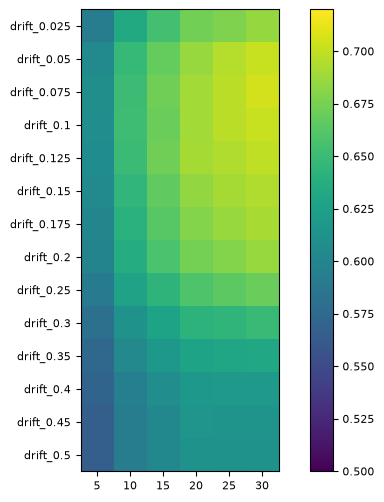

In [63]:
fig,ax = plt.subplots(figsize=(8,6))
im=ax.imshow(results_df_vary_drift_and_units_matrix.to_pandas().iloc[:,1:].values,aspect='equal',vmin=0.5,vmax=0.72)
ax.set_xticks(range(results_df_vary_drift_and_units_matrix.shape[1]-1))
ax.set_yticks(range(results_df_vary_drift_and_units_matrix.shape[0]))
ax.set_xticklabels(results_df_vary_drift_and_units_matrix.columns[1:])
ax.set_yticklabels(results_df_vary_drift_and_units_matrix['unit_criteria'])
fig.colorbar(im, ax=ax)